In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import statsmodels.api as sm

from src.data import *
from src.models import *
from src.features import log_returns, realised_volatility
from src.backtest import walk_forward
from src.metrics import compare_models, compare_models_staggered, dm_table

/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


### ==== Validation =====

In [2]:
spot = load_brent_spot(start="1987-01-01")
data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()


val_args = dict(horizon=60, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")


val_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    "Direct Forecast": walk_forward(data, forecast_funct=direct_forecast, lookback=3000, **val_args),
    "Direct Lag_1 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=1, long=60, lookback=3000, **val_args),
    "Direct Lag_5 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=5, long=60, lookback=3000, **val_args)
}

compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,5.289485,6.623020,7.328490,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,386
Historical Mean,5.154657,6.483503,7.110097,0.691275,0.000000,0.000000,0.000000,0.691275,1.000000,0.817460,0.117025,0.297832,0.392925,-0.263059,1.000000,0.000000,0.000000,386
AR,5.154056,6.481886,7.109355,0.686801,0.000000,0.000000,0.000000,0.689888,0.993528,0.814324,0.116296,0.295914,0.393006,-0.263059,0.989637,0.000000,0.087047,386
Direct Forecast,4.500004,5.786758,6.251301,0.760626,0.574879,0.862319,0.689855,0.920833,0.715210,0.805100,0.185171,0.156943,1.179857,-0.085754,0.464594,0.484456,6.310881,386
Direct Lag_1 Lag_60,4.491483,5.773978,6.239654,0.756152,0.570732,0.847826,0.682216,0.913223,0.715210,0.802178,0.186017,0.163460,1.138000,-0.085842,0.475130,0.479275,6.310881,386
Direct Lag_5 Lag_60,4.582147,5.881958,6.361988,0.747204,0.561576,0.826087,0.668622,0.901639,0.711974,0.795660,0.169139,0.160140,1.056197,-0.103066,0.452418,0.463731,6.158549,386


#### Mean Revert

In [3]:
# PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns
# INDICES = ["vix", "ovx", "epu", "gpr"]           # fear/uncertainty indices -> log levels

df_mr = load_dataset()
df_mr = df_mr[["brent_spot", "wti"]]
df_mr = df_mr.rename(columns={"wti": "wti_spot"})
df_mr["log_return"] = np.log(df_mr["brent_spot"]).diff()
df_mr = df_mr.dropna()

df_mr.tail()

,brent_spot,wti_spot,log_return
DATE,,,
2026-10-21,117.37,103.95,0.018488
2026-10-22,125.39,104.27,0.066098
2026-10-23,128.30,109.72,0.022942
2026-10-26,128.12,105.25,-0.001404
2026-10-27,123.10,103.37,-0.039970


In [4]:
val_forecast = walk_forward(df_mr, forecast_funct=spread_mr_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
442,2025-09-30,2025-12-23,68.52,66.423926,63.70
443,2025-10-01,2025-12-24,66.67,65.886152,63.70
444,2025-10-02,2025-12-29,65.44,64.490984,63.10
445,2025-10-03,2025-12-30,66.13,64.856800,62.30
446,2025-10-06,2025-12-31,67.09,65.733082,61.35


In [5]:
val_results["Mean Revert"] = val_forecast

compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,5.289485,6.623020,7.328490,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,386
Historical Mean,5.154657,6.483503,7.110097,0.691275,0.000000,0.000000,0.000000,0.691275,1.000000,0.817460,0.117025,0.297832,0.392925,-0.263059,1.000000,0.000000,0.000000,386
AR,5.154056,6.481886,7.109355,0.686801,0.000000,0.000000,0.000000,0.689888,0.993528,0.814324,0.116296,0.295914,0.393006,-0.263059,0.989637,0.000000,0.087047,386
Direct Forecast,4.500004,5.786758,6.251301,0.760626,0.574879,0.862319,0.689855,0.920833,0.715210,0.805100,0.185171,0.156943,1.179857,-0.085754,0.464594,0.484456,6.310881,386
Direct Lag_1 Lag_60,4.491483,5.773978,6.239654,0.756152,0.570732,0.847826,0.682216,0.913223,0.715210,0.802178,0.186017,0.163460,1.138000,-0.085842,0.475130,0.479275,6.310881,386
Direct Lag_5 Lag_60,4.582147,5.881958,6.361988,0.747204,0.561576,0.826087,0.668622,0.901639,0.711974,0.795660,0.169139,0.160140,1.056197,-0.103066,0.452418,0.463731,6.158549,386
Mean Revert,5.733417,7.105694,7.911128,0.373602,0.258503,0.550725,0.351852,0.594771,0.294498,0.393939,-0.092446,0.162778,-0.567928,-0.212217,0.508463,0.836788,3.917098,386


#### XGBoost

In [6]:
val_forecast = walk_forward(data, forecast_funct=xgb_direct_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
442,2025-09-30,2025-12-23,68.52,68.277684,63.70
443,2025-10-01,2025-12-24,66.67,66.654123,63.70
444,2025-10-02,2025-12-29,65.44,65.538555,63.10
445,2025-10-03,2025-12-30,66.13,66.221351,62.30
446,2025-10-06,2025-12-31,67.09,66.828761,61.35


In [7]:
val_results["XGBoost"] = val_forecast

compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,5.289485,6.623020,7.328490,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,386
Historical Mean,5.154657,6.483503,7.110097,0.691275,0.000000,0.000000,0.000000,0.691275,1.000000,0.817460,0.117025,0.297832,0.392925,-0.263059,1.000000,0.000000,0.000000,386
AR,5.154056,6.481886,7.109355,0.686801,0.000000,0.000000,0.000000,0.689888,0.993528,0.814324,0.116296,0.295914,0.393006,-0.263059,0.989637,0.000000,0.087047,386
Direct Forecast,4.500004,5.786758,6.251301,0.760626,0.574879,0.862319,0.689855,0.920833,0.715210,0.805100,0.185171,0.156943,1.179857,-0.085754,0.464594,0.484456,6.310881,386
Direct Lag_1 Lag_60,4.491483,5.773978,6.239654,0.756152,0.570732,0.847826,0.682216,0.913223,0.715210,0.802178,0.186017,0.163460,1.138000,-0.085842,0.475130,0.479275,6.310881,386
Direct Lag_5 Lag_60,4.582147,5.881958,6.361988,0.747204,0.561576,0.826087,0.668622,0.901639,0.711974,0.795660,0.169139,0.160140,1.056197,-0.103066,0.452418,0.463731,6.158549,386
Mean Revert,5.733417,7.105694,7.911128,0.373602,0.258503,0.550725,0.351852,0.594771,0.294498,0.393939,-0.092446,0.162778,-0.567928,-0.212217,0.508463,0.836788,3.917098,386
XGBoost,5.515697,6.967306,7.659239,0.655481,0.457895,0.630435,0.530488,0.801556,0.666667,0.727915,0.153012,0.222027,0.689158,-0.153228,0.694128,0.362694,4.417617,386


#### Direct Ridge Forecast

In [8]:
df_rr = load_dataset()
  
df_rr = df_rr[["brent_spot", "wti", "usd", "sp500", "vix", "ovx", "gpr"]]
df_rr["log_return"] = np.log(df_rr["brent_spot"]).diff()
df_rr = df_rr.rename(columns={"wti": "wti_spot"})
df_rr = df_rr.dropna()

for col in ["usd", "sp500", "vix", "ovx", "gpr"]:
    df_rr[col] = np.log(df_rr[col])

df_rr.tail()

,brent_spot,wti_spot,usd,sp500,vix,ovx,gpr,log_return
DATE,,,,,,,,
2026-10-21,117.37,103.95,4.798615,8.956373,2.814210,3.975561,5.500734,0.018488
2026-10-22,125.39,104.27,4.798704,8.944215,2.946017,4.018902,5.482422,0.066098
2026-10-23,128.30,109.72,4.798433,8.939014,2.967847,4.094678,5.187708,0.022942
2026-10-26,128.12,105.25,4.798433,8.945954,2.911807,4.072610,5.107476,-0.001404
2026-10-27,123.10,103.37,4.798433,8.951906,2.863343,4.015301,5.107476,-0.039970


In [9]:
val_forecast = walk_forward(df_rr, forecast_funct=direct_ridge_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
442,2025-09-30,2025-12-23,68.52,68.014118,63.70
443,2025-10-01,2025-12-24,66.67,66.725393,63.70
444,2025-10-02,2025-12-29,65.44,65.615801,63.10
445,2025-10-03,2025-12-30,66.13,66.188236,62.30
446,2025-10-06,2025-12-31,67.09,66.608456,61.35


In [10]:
val_results["Direct Ridge"] = val_forecast

compare_models_staggered(val_results,  horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,5.289485,6.623020,7.328490,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,386
Historical Mean,5.154657,6.483503,7.110097,0.691275,0.000000,0.000000,0.000000,0.691275,1.000000,0.817460,0.117025,0.297832,0.392925,-0.263059,1.000000,0.000000,0.000000,386
AR,5.154056,6.481886,7.109355,0.686801,0.000000,0.000000,0.000000,0.689888,0.993528,0.814324,0.116296,0.295914,0.393006,-0.263059,0.989637,0.000000,0.087047,386
Direct Forecast,4.500004,5.786758,6.251301,0.760626,0.574879,0.862319,0.689855,0.920833,0.715210,0.805100,0.185171,0.156943,1.179857,-0.085754,0.464594,0.484456,6.310881,386
Direct Lag_1 Lag_60,4.491483,5.773978,6.239654,0.756152,0.570732,0.847826,0.682216,0.913223,0.715210,0.802178,0.186017,0.163460,1.138000,-0.085842,0.475130,0.479275,6.310881,386
Direct Lag_5 Lag_60,4.582147,5.881958,6.361988,0.747204,0.561576,0.826087,0.668622,0.901639,0.711974,0.795660,0.169139,0.160140,1.056197,-0.103066,0.452418,0.463731,6.158549,386
Mean Revert,5.733417,7.105694,7.911128,0.373602,0.258503,0.550725,0.351852,0.594771,0.294498,0.393939,-0.092446,0.162778,-0.567928,-0.212217,0.508463,0.836788,3.917098,386
XGBoost,5.515697,6.967306,7.659239,0.655481,0.457895,0.630435,0.530488,0.801556,0.666667,0.727915,0.153012,0.222027,0.689158,-0.153228,0.694128,0.362694,4.417617,386
Direct Ridge,5.124730,6.505705,7.075019,0.664430,0.469388,0.666667,0.550898,0.816733,0.663430,0.732143,0.119544,0.198495,0.602253,-0.148793,0.549136,0.437824,5.113990,386


#### Combination Forecast

In [11]:
weights = [0.1, 0.35, 0.2, 0.35]
val_forecast = walk_forward(data, forecast_funct=combination_forecast, weights=weights, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
442,2025-09-30,2025-12-23,68.52,68.500854,63.70
443,2025-10-01,2025-12-24,66.67,67.068334,63.70
444,2025-10-02,2025-12-29,65.44,66.022339,63.10
445,2025-10-03,2025-12-30,66.13,66.397878,62.30
446,2025-10-06,2025-12-31,67.09,67.418579,61.35


In [12]:
val_results["Combination"] = val_forecast

compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,5.289485,6.623020,7.328490,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,386
Historical Mean,5.154657,6.483503,7.110097,0.691275,0.000000,0.000000,0.000000,0.691275,1.000000,0.817460,0.117025,0.297832,0.392925,-0.263059,1.000000,0.000000,0.000000,386
AR,5.154056,6.481886,7.109355,0.686801,0.000000,0.000000,0.000000,0.689888,0.993528,0.814324,0.116296,0.295914,0.393006,-0.263059,0.989637,0.000000,0.087047,386
Direct Forecast,4.500004,5.786758,6.251301,0.760626,0.574879,0.862319,0.689855,0.920833,0.715210,0.805100,0.185171,0.156943,1.179857,-0.085754,0.464594,0.484456,6.310881,386
Direct Lag_1 Lag_60,4.491483,5.773978,6.239654,0.756152,0.570732,0.847826,0.682216,0.913223,0.715210,0.802178,0.186017,0.163460,1.138000,-0.085842,0.475130,0.479275,6.310881,386
Direct Lag_5 Lag_60,4.582147,5.881958,6.361988,0.747204,0.561576,0.826087,0.668622,0.901639,0.711974,0.795660,0.169139,0.160140,1.056197,-0.103066,0.452418,0.463731,6.158549,386
Mean Revert,5.733417,7.105694,7.911128,0.373602,0.258503,0.550725,0.351852,0.594771,0.294498,0.393939,-0.092446,0.162778,-0.567928,-0.212217,0.508463,0.836788,3.917098,386
XGBoost,5.515697,6.967306,7.659239,0.655481,0.457895,0.630435,0.530488,0.801556,0.666667,0.727915,0.153012,0.222027,0.689158,-0.153228,0.694128,0.362694,4.417617,386
Direct Ridge,5.124730,6.505705,7.075019,0.664430,0.469388,0.666667,0.550898,0.816733,0.663430,0.732143,0.119544,0.198495,0.602253,-0.148793,0.549136,0.437824,5.113990,386


### ==== Diebold-Mariano test ====

In [13]:
for loss in ["ae", "se"]:
    print(f"\nDM test vs Random Walk, loss = {loss}")
    print(dm_table(val_results, benchmark="Random Walk", horizon=60, loss=loss).round(4))


DM test vs Random Walk, loss = ae
                     DM_stat  p_value      n
Historical Mean      -1.3167   0.1886  447.0
AR                   -1.3317   0.1837  447.0
Direct Forecast      -2.9730   0.0031  447.0
Direct Lag_1 Lag_60  -2.9359   0.0035  447.0
Direct Lag_5 Lag_60  -2.3706   0.0182  447.0
Mean Revert           2.1278   0.0339  447.0
XGBoost               0.4968   0.6196  447.0
Direct Ridge         -1.4972   0.1350  447.0
Combination          -4.5030   0.0000  447.0

DM test vs Random Walk, loss = se
                     DM_stat  p_value      n
Historical Mean      -1.3167   0.1886  447.0
AR                   -1.3317   0.1837  447.0
Direct Forecast      -2.9730   0.0031  447.0
Direct Lag_1 Lag_60  -2.9359   0.0035  447.0
Direct Lag_5 Lag_60  -2.3706   0.0182  447.0
Mean Revert           2.1278   0.0339  447.0
XGBoost               0.4968   0.6196  447.0
Direct Ridge         -1.4972   0.1350  447.0
Combination          -4.5030   0.0000  447.0


In [14]:
from src.features import garch_volatility
from src.metrics import compare_vol_regimes

keys = {name: val_results[name] for name in
         ["Random Walk", "Historical Mean", "AR", "Direct Forecast", "Direct Lag_1 Lag_60", "Direct Ridge", "XGBoost", "Combination"]}
volatility = garch_volatility(df_rr, col="log_return")
compare_vol_regimes(keys, volatility)[["MAPE_low_vol", "MAPE_high_vol"]].round(4)

,MAPE_low_vol,MAPE_high_vol
Random Walk,8.3108,6.3506
Historical Mean,7.8999,6.3238
AR,7.8995,6.3227
Direct Forecast,7.3361,5.1713
Direct Lag_1 Lag_60,7.2966,5.1875
Direct Ridge,8.1381,6.0166
XGBoost,6.4252,8.8878
Combination,6.9440,5.4891


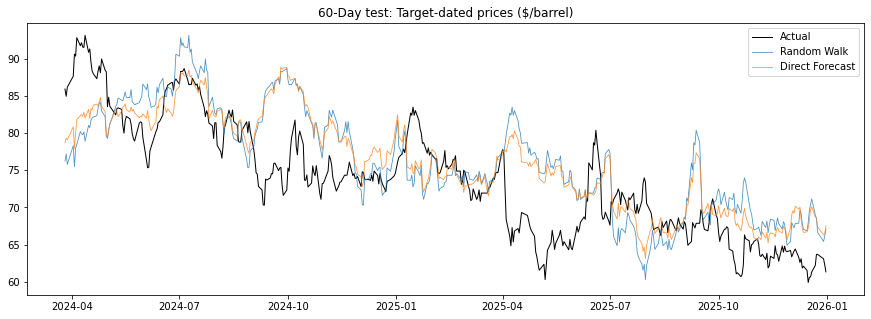

In [20]:
plt.figure(figsize=(15, 5))
plt.plot(np.array(val_results["Random Walk"]["target_date"]), np.array(val_results["Random Walk"]["actual"]), label='Actual', color='black', lw=1)

for name in ["Random Walk", "Direct Forecast"]:
    r = val_results[name]
    plt.plot(np.array(r["target_date"]), np.array(r["forecast"]), label=name, alpha=0.8, lw=0.8)

plt.title("60-Day test: Target-dated prices ($/barrel)")
plt.legend(loc="upper right")
plt.show()

### ==== Test ====

In [16]:
test_args = dict(horizon=60, start_date="2026-01-01", end_date="2026-09-30", target_end_date="2026-09-30")

test_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    "Direct Forecast": walk_forward(data, forecast_funct=direct_forecast, lookback=3000, **test_args),
    "Direct Lag_1 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=1, long=60, lookback=3000, **test_args),
    "Direct Lag_5 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=5, long=60, lookback=3000, **test_args),
    "Mean Revert": walk_forward(df_mr, forecast_funct=spread_mr_forecast, lookback=3000, **test_args),
    "XGBoost": walk_forward(data, forecast_funct=xgb_direct_forecast, lookback=3000, **test_args),
    "Direct Ridge": walk_forward(df_rr, forecast_funct=direct_ridge_forecast, lookback=3000, **test_args),
    "Combination": walk_forward(data, forecast_funct=combination_forecast, weights=weights, **test_args)
}

compare_models_staggered(test_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,32.663333,37.088322,32.955882,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,68
Historical Mean,32.970212,37.448324,33.241586,0.178295,0.000000,0.000000,0.000000,0.244681,0.396552,0.302632,-0.236307,0.297672,-0.793849,-0.126796,0.256863,0.397059,5.311765,68
AR,32.969282,37.443084,33.240413,0.170543,0.000000,0.000000,0.000000,0.236559,0.379310,0.291391,-0.263378,0.279524,-0.942237,-0.127746,0.246569,0.426471,5.435294,68
Direct Forecast,26.784257,32.426083,25.841311,0.635659,1.000000,0.338028,0.505263,0.552381,1.000000,0.711656,1.567296,0.646659,2.423684,-0.215947,0.903922,0.000000,2.841176,68
Direct Lag_1 Lag_60,26.469949,32.113053,25.588352,0.627907,1.000000,0.323944,0.489362,0.547170,1.000000,0.707317,1.568969,0.647533,2.422993,-0.215947,0.905392,0.000000,2.717647,68
Direct Lag_5 Lag_60,26.456992,32.120494,25.550504,0.612403,0.920000,0.323944,0.479167,0.538462,0.965517,0.691358,1.494124,0.642790,2.324436,-0.215947,0.883333,0.000000,2.964706,68
Mean Revert,30.728036,35.471597,30.230755,0.472868,0.533333,0.338028,0.413793,0.440476,0.637931,0.521127,0.546368,0.525735,1.039246,-0.196157,0.561765,0.161765,4.694118,68
XGBoost,37.767243,42.116770,39.954089,0.480620,0.516667,0.873239,0.649215,0.000000,0.000000,0.000000,-1.703112,0.634519,-2.684098,-0.489858,0.973529,1.000000,1.111765,68
Direct Ridge,32.530561,37.042527,32.801530,0.612403,0.723404,0.478873,0.576271,0.548780,0.775862,0.642857,0.810825,0.184885,4.385575,-0.032892,0.298039,0.294118,3.582353,68


In [17]:
keys = {name: test_results[name] for name in
         ["Random Walk", "Historical Mean", "AR", "Direct Forecast", "Direct Lag_1 Lag_60", "Direct Ridge", "XGBoost", "Combination"]}
volatility = garch_volatility(df_rr, col="log_return")
compare_vol_regimes(keys, volatility)[["MAPE_low_vol", "MAPE_high_vol"]].round(4)

,MAPE_low_vol,MAPE_high_vol
Random Walk,35.1374,30.8079
Historical Mean,35.6037,30.9158
AR,35.6044,30.9128
Direct Forecast,34.6066,17.2109
Direct Lag_1 Lag_60,34.0143,17.2921
Direct Ridge,35.1130,30.5256
XGBoost,31.0003,48.7702
Combination,33.6983,23.3778


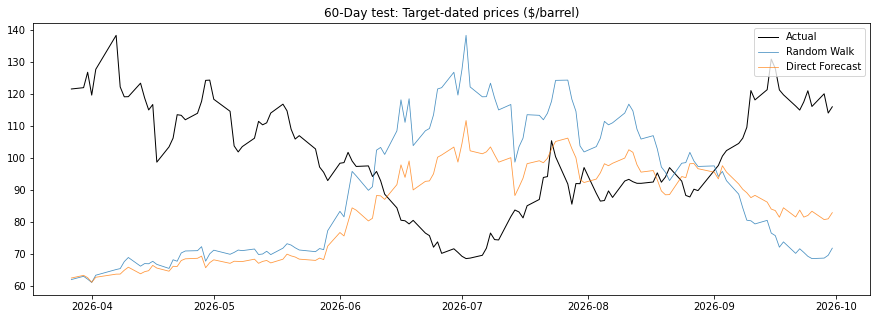

In [18]:
plt.figure(figsize=(15, 5))
plt.plot(np.array(test_results["Random Walk"]["target_date"]), np.array(test_results["Random Walk"]["actual"]), label='Actual', color='black', lw=1)

for name in ["Random Walk", "Direct Forecast"]:
    r = test_results[name]
    plt.plot(np.array(r["target_date"]), np.array(r["forecast"]), label=name, alpha=0.8, lw=0.8)

plt.title("60-Day test: Target-dated prices ($/barrel)")
plt.legend(loc="upper right")
plt.show()

### ==== Final 60-day forecast =====
origin = 2026-09-30

In [19]:
from src.final_forecast import direct_report, final_forecast, make_model

# Direct forecast with the OLS table, parameter CI and prediction interval 
# final_forecast = direct_report(data, horizon=60, origin_date="2026-09-30", lookback=3000)

# Model with a GARCH interval
# Switching models: "direct", "direct_lags", "xgboost", "combination" or "random_walk"
final = final_forecast(data, make_model("direct", 60, lookbakc=3000), horizon=60, origin_date="2026-09-30")

Origin 2026-09-30   price = 115.91
Horizon: 60 trading days  (target ~ 2026-12-23)
Predicted 60-day log return = -0.1497
Point forecast : 99.79   (random walk: 115.91)
95% prediction interval (garch): 62.76 to 158.68

19 trading days elapsed. Latest 2026-10-27: 123.10 (realised log return +0.0602)
